# LeakageLab: Investigating Feature Selection Leakage

**Project type:** Independent experimental ML research project

## Research question
How does performing feature selection before the train/test split affect evaluation, and how does the number of candidate features influence the observed effect?

**Important:** The intentionally leaky workflow is included only as a demonstration. It must not be used for real model evaluation.

## Concept

In the correct workflow, split observations first and fit feature selection only on training data and labels. In the leaky workflow, feature selection uses the entire dataset, including test labels, before splitting. This allows test-label information to influence feature selection and compromises the independence of the test evaluation.

## Setup

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_breast_cancer

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


## Experiment A - One synthetic dataset

In [18]:
rng = np.random.default_rng(42)
X_random = rng.normal(size=(500, 100))
y_random = rng.integers(0, 2, size=500)
indices = np.arange(len(y_random))
train_idx, test_idx = train_test_split(indices, test_size=0.30, random_state=7, stratify=y_random)

correct = make_pipeline(SelectKBest(f_classif, k=10), LogisticRegression(max_iter=1000))
correct.fit(X_random[train_idx], y_random[train_idx])
correct_acc = accuracy_score(y_random[test_idx], correct.predict(X_random[test_idx]))

# Intentionally leaky: selector sees all labels, including test labels.
selector = SelectKBest(f_classif, k=10)
X_selected = selector.fit_transform(X_random, y_random)
leaky = LogisticRegression(max_iter=1000)
leaky.fit(X_selected[train_idx], y_random[train_idx])
leaky_acc = accuracy_score(y_random[test_idx], leaky.predict(X_selected[test_idx]))

print(f"Correct workflow accuracy: {correct_acc:.3f}")
print(f"Leaky workflow accuracy: {leaky_acc:.3f}")
print("Chance reference: 0.500")

Correct workflow accuracy: 0.500
Leaky workflow accuracy: 0.573
Chance reference: 0.500


## Reusable comparison function

In [19]:
def compare_workflows(X, y, train_idx, test_idx, k):
    correct = make_pipeline(SelectKBest(f_classif, k=k), LogisticRegression(max_iter=5000))
    correct.fit(X[train_idx], y[train_idx])
    correct_score = accuracy_score(y[test_idx], correct.predict(X[test_idx]))

    # Deliberately leaky comparison
    X_selected = SelectKBest(f_classif, k=k).fit_transform(X, y)
    leaky = LogisticRegression(max_iter=5000)
    leaky.fit(X_selected[train_idx], y[train_idx])
    leaky_score = accuracy_score(y[test_idx], leaky.predict(X_selected[test_idx]))
    return correct_score, leaky_score

## Synthetic experiments: 50 trials per feature count

,candidate_features,correct_mean,leaky_mean,gap_percentage_points
0,20,0.495,0.531,3.587
1,100,0.514,0.590,7.667
2,500,0.502,0.629,12.667


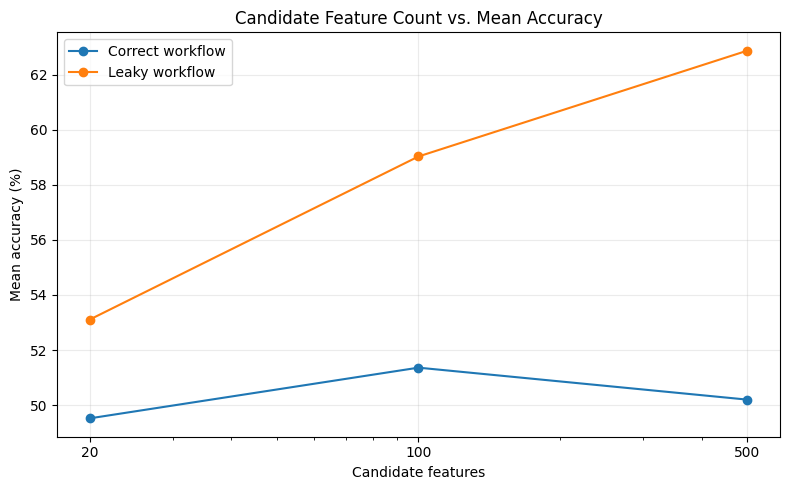

Synthetic CSV files and graph saved successfully.


In [20]:
from pathlib import Path

FIGURES_DIR = Path("figures")
RESULTS_DIR = Path("results")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
runs = []
for n_features in [20, 100, 500]:
    for seed in range(50):
        rng = np.random.default_rng(seed)
        X = rng.normal(size=(500, n_features))
        y = rng.integers(0, 2, size=500)
        idx = np.arange(len(y))
        train_idx, test_idx = train_test_split(idx, test_size=0.30, random_state=7, stratify=y)
        c, l = compare_workflows(X, y, train_idx, test_idx, k=10)
        runs.append({"candidate_features": n_features, "seed": seed,
                     "correct_accuracy": c, "leaky_accuracy": l,
                     "difference_pp": 100*(l-c)})

synthetic_df = pd.DataFrame(runs)
summary = synthetic_df.groupby("candidate_features").agg(
    correct_mean=("correct_accuracy","mean"),
    leaky_mean=("leaky_accuracy","mean"),
    gap_percentage_points=("difference_pp","mean")
).reset_index()
display(summary.round(3))

plt.figure(figsize=(8,5))
plt.plot(summary.candidate_features, 100*summary.correct_mean, marker="o", label="Correct workflow")
plt.plot(summary.candidate_features, 100*summary.leaky_mean, marker="o", label="Leaky workflow")
plt.xscale("log")
plt.xticks([20,100,500],["20","100","500"])
plt.xlabel("Candidate features")
plt.ylabel("Mean accuracy (%)")
plt.title("Candidate Feature Count vs. Mean Accuracy")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()

# Export synthetic results into results/
synthetic_df.to_csv(
    RESULTS_DIR / "synthetic_feature_count_all_trials.csv",
    index=False
)

summary.to_csv(
    RESULTS_DIR / "synthetic_feature_count_results.csv",
    index=False
)

# Save graph into figures/
plt.savefig(
    FIGURES_DIR / "synthetic_feature_count_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Synthetic CSV files and graph saved successfully.")

### Previously observed synthetic results

| Candidate features | Correct mean | Leaky mean | Gap (percentage points) |
|---:|---:|---:|---:|
| 20 | 0.495 | 0.531 | 3.587 |
| 100 | 0.514 | 0.590 | 7.667 |
| 500 | 0.502 | 0.629 | 12.667 |

These are the values observed in the initial project run. Use fresh notebook outputs if a rerun differs; do not silently combine the two sets.

## Real dataset: Breast Cancer Wisconsin Diagnostic

Dataset shape: (569, 30)
Mean correct accuracy: 0.931
Mean leaky accuracy: 0.935
Mean difference (percentage points): 0.363
Median difference: 0.0
Standard deviation: 1.082
Leaky higher / equal / lower: 6 / 44 / 0


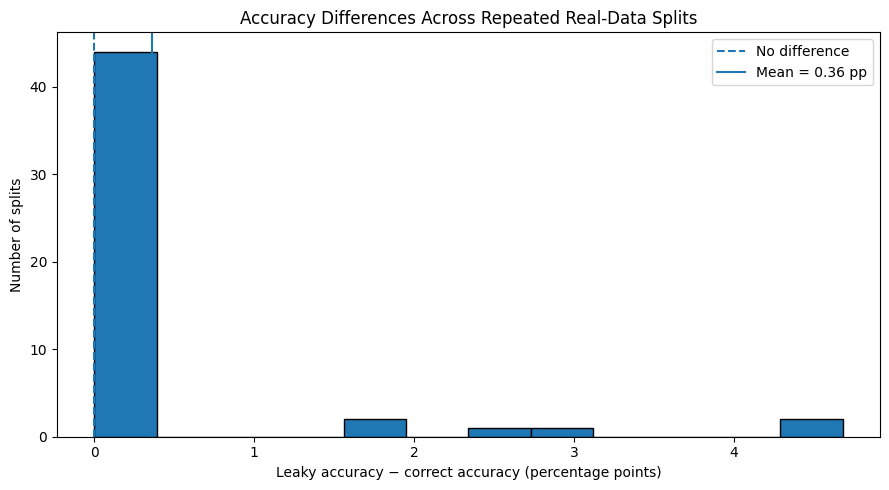

Real-dataset CSV files and graph saved successfully.


,observations,features,selected_features,repeated_splits,correct_mean_accuracy,leaky_mean_accuracy,mean_difference_pp,median_difference_pp,std_difference_pp,leaky_higher,equal,leaky_lower
0,569,30,5,50,0.9312,0.9349,0.3626,0.0,1.0821,6,44,0


In [21]:
data = load_breast_cancer()
X_real, y_real = data.data, data.target
real_runs = []

for seed in range(50):
    idx = np.arange(len(y_real))
    train_idx, test_idx = train_test_split(idx, test_size=0.30, random_state=seed, stratify=y_real)
    c, l = compare_workflows(X_real, y_real, train_idx, test_idx, k=5)
    real_runs.append({"seed":seed, "correct_accuracy":c, "leaky_accuracy":l,
                      "difference_pp":100*(l-c)})

real_df = pd.DataFrame(real_runs)
d = real_df.difference_pp.to_numpy()
print("Dataset shape:", X_real.shape)
print("Mean correct accuracy:", round(real_df.correct_accuracy.mean(),3))
print("Mean leaky accuracy:", round(real_df.leaky_accuracy.mean(),3))
print("Mean difference (percentage points):", round(d.mean(),3))
print("Median difference:", round(np.median(d),3))
print("Standard deviation:", round(d.std(ddof=1),3))
print("Leaky higher / equal / lower:",
      int((d>0).sum()), "/", int((d==0).sum()), "/", int((d<0).sum()))

plt.figure(figsize=(9,5))
plt.hist(d, bins=12, edgecolor="black")
plt.axvline(0, linestyle="--", label="No difference")
plt.axvline(d.mean(), linestyle="-", label=f"Mean = {d.mean():.2f} pp")
plt.xlabel("Leaky accuracy − correct accuracy (percentage points)")
plt.ylabel("Number of splits")
plt.title("Accuracy Differences Across Repeated Real-Data Splits")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "real_dataset_accuracy_differences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export all 50 individual comparisons
real_df.to_csv(
    RESULTS_DIR / "real_dataset_all_trials.csv",
    index=False
)

# Create a fresh one-row summary from the current run
real_summary = pd.DataFrame([{
    "observations": X_real.shape[0],
    "features": X_real.shape[1],
    "selected_features": 5,
    "repeated_splits": len(real_df),
    "correct_mean_accuracy": real_df["correct_accuracy"].mean(),
    "leaky_mean_accuracy": real_df["leaky_accuracy"].mean(),
    "mean_difference_pp": d.mean(),
    "median_difference_pp": np.median(d),
    "std_difference_pp": d.std(ddof=1),
    "leaky_higher": int((d > 0).sum()),
    "equal": int((d == 0).sum()),
    "leaky_lower": int((d < 0).sum())
}])

real_summary.to_csv(
    RESULTS_DIR / "real_dataset_reported_summary.csv",
    index=False
)

print("Real-dataset CSV files and graph saved successfully.")
display(real_summary.round(4))

### Optional: Export all results as a ZIP file

In [25]:
import os

output_files = [
    RESULTS_DIR / "synthetic_feature_count_all_trials.csv",
    RESULTS_DIR / "synthetic_feature_count_results.csv",
    FIGURES_DIR / "synthetic_feature_count_accuracy.png",
    RESULTS_DIR / "real_dataset_all_trials.csv",
    RESULTS_DIR / "real_dataset_reported_summary.csv",
    FIGURES_DIR / "real_dataset_accuracy_differences.png"
]

for path in output_files:
    print(
        path,
        "—",
        "FOUND" if path.exists() else "MISSING"
    )

results/synthetic_feature_count_all_trials.csv — FOUND
results/synthetic_feature_count_results.csv — FOUND
figures/synthetic_feature_count_accuracy.png — FOUND
results/real_dataset_all_trials.csv — FOUND
results/real_dataset_reported_summary.csv — FOUND
figures/real_dataset_accuracy_differences.png — FOUND


In [26]:
import zipfile
from google.colab import files

with zipfile.ZipFile(
    "LeakageLab_fresh_results.zip", "w"
) as archive:
    for path in output_files:
        if not path.exists():
            raise FileNotFoundError(f"Missing file: {path}")

        archive.write(path, arcname=str(path))

files.download("LeakageLab_fresh_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Previously observed real-data results

- Dataset: 569 observations and 30 features
- Features selected: 5
- Repeated splits: 50
- Correct mean accuracy: 0.931
- Leaky mean accuracy: 0.935
- Mean difference: 0.363 percentage points
- Median difference: 0.0 percentage points
- Standard deviation: 1.082 percentage points
- Leaky higher / equal / lower: 6 / 44 / 0

An approximate 95% t-interval previously calculated for the mean difference was [0.055, 0.670] percentage points. This interval assumes independent paired differences, but the 50 splits reuse the same observations. Treat it as descriptive, not as definitive evidence of statistical significance.

## Discussion and limitations

The synthetic experiments showed higher mean accuracy for the leaky workflow, with the observed gap increasing as candidate feature count grew. On the real dataset, the average gap was much smaller and most splits produced equal accuracy.

Limitations:
1. Synthetic features and labels were independent random variables; results may not generalize to other distributions.
2. Only one feature-selection method and one classifier were tested.
3. Only one real dataset was evaluated.
4. Accuracy does not capture every dimension of model quality.
5. Repeated splits reuse the same observations and are not independent datasets.
6. The approximate t-interval does not account adequately for dependence between splits.
7. The experiments do not establish that leakage always increases accuracy.

## Conclusion

Under the tested synthetic conditions, the leaky workflow had higher mean accuracy and the gap increased with candidate feature count. On the real dataset, the average difference was much smaller. These findings illustrate that leakage can make evaluation optimistic, but its observed magnitude depends on the dataset and experimental setting.

**Recommended practice:** split first; fit feature selection and other learned preprocessing only on training data; then evaluate on held-out test data.

## Reproducibility checklist

- Run all cells from top to bottom in a fresh runtime.
- Compare fresh outputs with the previously recorded results.
- Keep the leaky workflow labeled as demonstration-only.
- Update the README if fresh outputs differ.
- Do not claim statistical significance from the approximate repeated-split interval.